Approximate value = 1.4001618527804232
Exact value = 1.4056476493802699
Error = 0.005485796599846715


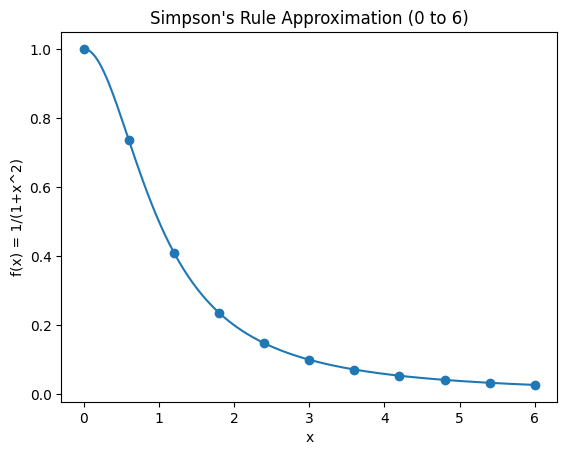

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 1 / (1 + x**2)

def simpsons_rule(a, b, n):
    if n % 2 != 0:
        print("Error: n must be even")
        return None

    h = (b - a) / n
    s = f(a) + f(b)

    for i in range(1, n, 2):
        s += 4 * f(a + i * h)

    for i in range(2, n, 2):
        s += 2 * f(a + i * h)

    return (h / 3) * s

# 🔹 Inputs
a = 0
b = 6
n = 10   # must be even

# 🔹 Simpson Result
result = simpsons_rule(a, b, n)

# 🔹 Exact Value
exact = np.arctan(6) - np.arctan(0)

print("Approximate value =", result)
print("Exact value =", exact)
print("Error =", abs(result - exact))

# 🔹 Graph
x = np.linspace(a, b, 200)
y = f(x)

x_points = np.linspace(a, b, n+1)
y_points = f(x_points)

plt.figure()
plt.plot(x, y)
plt.scatter(x_points, y_points)
plt.title("Simpson's Rule Approximation (0 to 6)")
plt.xlabel("x")
plt.ylabel("f(x) = 1/(1+x^2)")
plt.show()

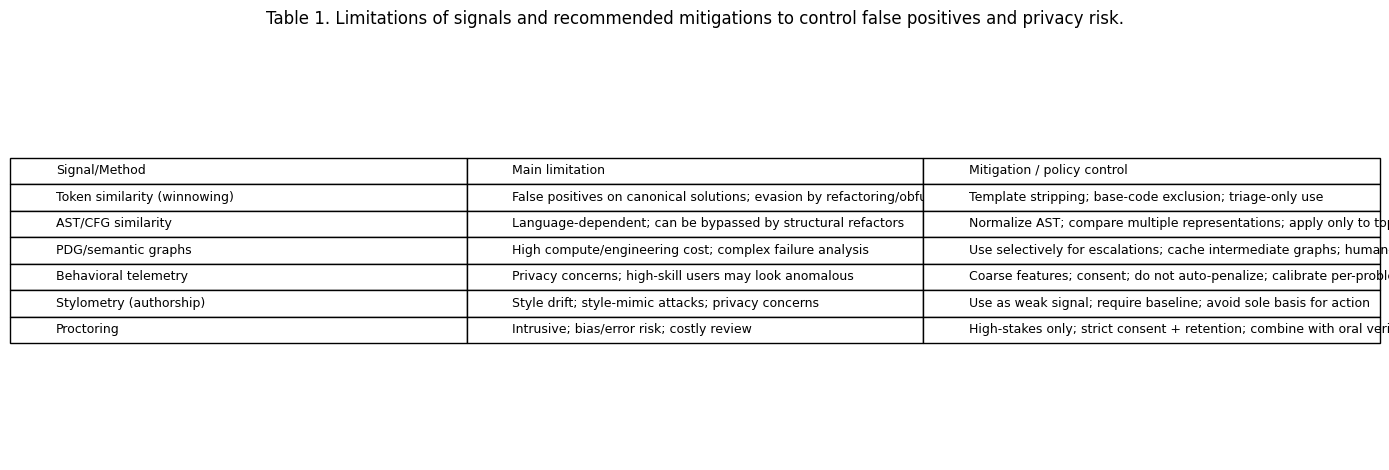

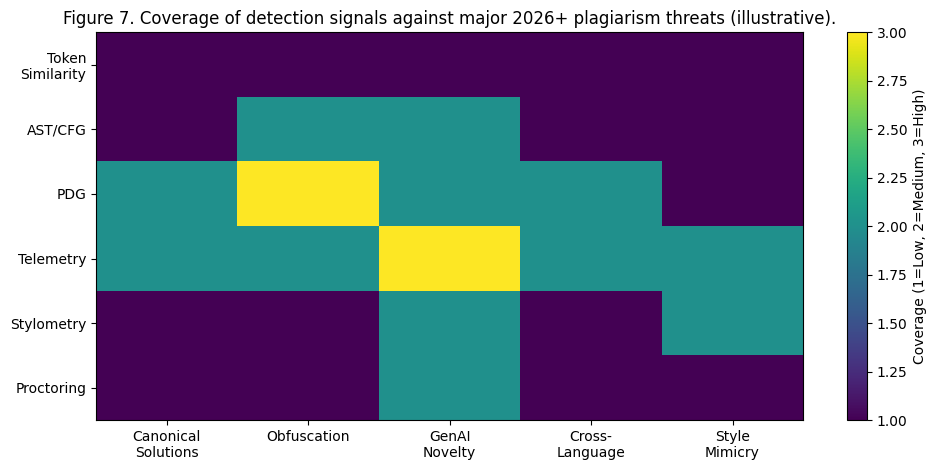

/tmp/ipykernel_434/2688009930.py:72: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([honest, suspicious], labels=["Honest", "Flagged/Suspicious"])


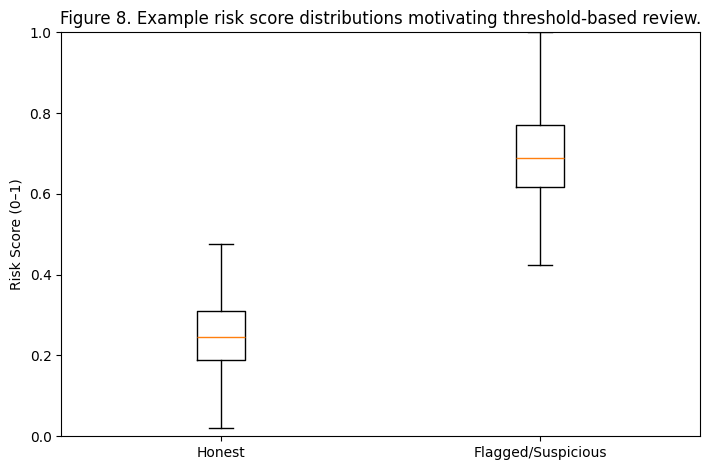

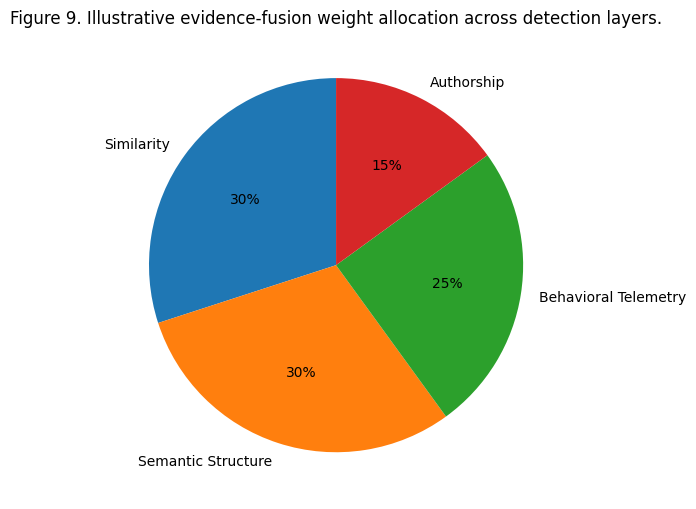

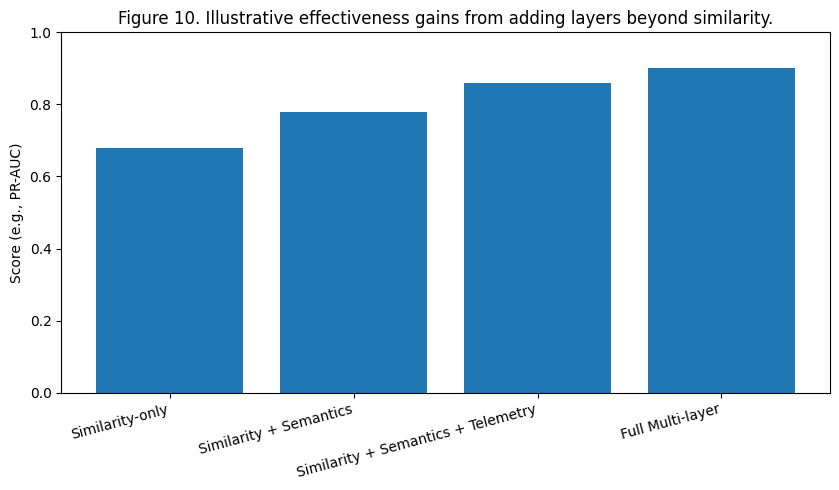

Saved files:
- Table1_Limitations_Mitigations.png
- Figure7_ThreatCoverage_Heatmap.png
- Figure8_RiskScore_Boxplot.png
- Figure9_FusionWeights_Pie.png
- Figure10_MethodComparison_Bar.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# TABLE 1: Limitations and mitigations
# -----------------------------
table1 = pd.DataFrame([
    ["Token similarity (winnowing)", "False positives on canonical solutions; evasion by refactoring/obfuscation", "Template stripping; base-code exclusion; triage-only use"],
    ["AST/CFG similarity", "Language-dependent; can be bypassed by structural refactors", "Normalize AST; compare multiple representations; apply only to top-risk clusters"],
    ["PDG/semantic graphs", "High compute/engineering cost; complex failure analysis", "Use selectively for escalations; cache intermediate graphs; human-in-the-loop review"],
    ["Behavioral telemetry", "Privacy concerns; high-skill users may look anomalous", "Coarse features; consent; do not auto-penalize; calibrate per-problem distributions"],
    ["Stylometry (authorship)", "Style drift; style-mimic attacks; privacy concerns", "Use as weak signal; require baseline; avoid sole basis for action"],
    ["Proctoring", "Intrusive; bias/error risk; costly review", "High-stakes only; strict consent + retention; combine with oral verification"]
], columns=["Signal/Method", "Main limitation", "Mitigation / policy control"])

# Render Table 1 as an image (good for papers)
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.axis("off")
tbl = ax.table(
    cellText=table1.values,
    colLabels=table1.columns,
    cellLoc="left",
    colLoc="left",
    loc="center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.4)
plt.title("Table 1. Limitations of signals and recommended mitigations to control false positives and privacy risk.", pad=12)
plt.tight_layout()
plt.savefig("Table1_Limitations_Mitigations.png", dpi=300)
plt.show()


# -----------------------------
# FIGURE 7: Heatmap (signal vs threat coverage)
# -----------------------------
signals = ["Token\nSimilarity", "AST/CFG", "PDG", "Telemetry", "Stylometry", "Proctoring"]
threats  = ["Canonical\nSolutions", "Obfuscation", "GenAI\nNovelty", "Cross-\nLanguage", "Style\nMimicry"]

# 1=low, 2=medium, 3=high coverage (example values; adjust if you want)
coverage = np.array([
    [1, 1, 1, 1, 1],  # Token similarity
    [1, 2, 2, 1, 1],  # AST/CFG
    [2, 3, 2, 2, 1],  # PDG
    [2, 2, 3, 2, 2],  # Telemetry
    [1, 1, 2, 1, 2],  # Stylometry
    [1, 1, 2, 1, 1]   # Proctoring
], dtype=float)

plt.figure(figsize=(10, 4.8))
plt.imshow(coverage, aspect="auto")
plt.xticks(range(len(threats)), threats)
plt.yticks(range(len(signals)), signals)
plt.colorbar(label="Coverage (1=Low, 2=Medium, 3=High)")
plt.title("Figure 7. Coverage of detection signals against major 2026+ plagiarism threats (illustrative).")
plt.tight_layout()
plt.savefig("Figure7_ThreatCoverage_Heatmap.png", dpi=300)
plt.show()


# -----------------------------
# FIGURE 8: Box plot (risk score distributions)
# -----------------------------
np.random.seed(7)
# Example distributions: Honest vs Suspicious. Replace with real scores if you have them.
honest = np.clip(np.random.normal(loc=0.25, scale=0.10, size=250), 0, 1)
suspicious = np.clip(np.random.normal(loc=0.70, scale=0.12, size=120), 0, 1)

plt.figure(figsize=(7.2, 4.8))
plt.boxplot([honest, suspicious], labels=["Honest", "Flagged/Suspicious"])
plt.ylim(0, 1)
plt.title("Figure 8. Example risk score distributions motivating threshold-based review.")
plt.ylabel("Risk Score (0–1)")
plt.tight_layout()
plt.savefig("Figure8_RiskScore_Boxplot.png", dpi=300)
plt.show()


# -----------------------------
# FIGURE 9: Pie chart (evidence fusion weights)
# -----------------------------
labels = ["Similarity", "Semantic Structure", "Behavioral Telemetry", "Authorship"]
weights = [0.30, 0.30, 0.25, 0.15]  # example fusion weights; adjust to match your paper

plt.figure(figsize=(6.5, 5.2))
plt.pie(weights, labels=labels, autopct="%1.0f%%", startangle=90)
plt.title("Figure 9. Illustrative evidence-fusion weight allocation across detection layers.")
plt.tight_layout()
plt.savefig("Figure9_FusionWeights_Pie.png", dpi=300)
plt.show()


# -----------------------------
# FIGURE 10: Bar chart (Similarity-only vs Multi-layer)
# -----------------------------
methods = ["Similarity-only", "Similarity + Semantics", "Similarity + Semantics + Telemetry", "Full Multi-layer"]
# Example values (PR-AUC / F1 / or any metric you report). Replace with real evaluation results if available.
scores = [0.68, 0.78, 0.86, 0.90]

plt.figure(figsize=(8.5, 5))
plt.bar(methods, scores)
plt.ylim(0, 1)
plt.title("Figure 10. Illustrative effectiveness gains from adding layers beyond similarity.")
plt.ylabel("Score (e.g., PR-AUC)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("Figure10_MethodComparison_Bar.png", dpi=300)
plt.show()

print("Saved files:")
print("- Table1_Limitations_Mitigations.png")
print("- Figure7_ThreatCoverage_Heatmap.png")
print("- Figure8_RiskScore_Boxplot.png")
print("- Figure9_FusionWeights_Pie.png")
print("- Figure10_MethodComparison_Bar.png")